# Notebook 7 — Final Comparison: All Models, Synthetic **and** Real Data

**What this notebook is.** The last step of the pipeline. It loads the per-sample result files saved by the earlier
notebooks and recomputes every comparison in one place — **no GPU and no API calls**, so it runs in seconds and every
output below was produced by running it.

| Input file | Written by | Contents |
|---|---|---|
| `all_models_results.csv` | Notebook 4 | synthetic test results: Qwen3-8B, Llama-3.1-8B, GLM-Z1-9B (500 each) + Qwen3-8B-FT (470) |
| `Finetunning/result with RD qwen-ft/ft-real_benchmark_results_real_001.csv` | Notebooks 5 + 6 | real-data results: 4 base models + Qwen3-8B-FT, 200 samples each |
| Notebook 3, last cell (printed output) | Notebook 3 | Gemini-3.5-Flash-Lite's synthetic summary (its per-sample file is not in the repo) |

**Structure**

| Part | Question |
|---|---|
| **A · Synthetic** | How robust is the published ranking (composite 0.651 / 0.586 / 0.582 / 0.426)? |
| **B · Real** | What do the 5 models really score on Apache Jira data, once the known scoring problems are corrected? |
| **C · Synthetic vs real** | Does the synthetic ranking — and the fine-tuning gain — carry over to real data? |
| **D · Conclusions** | What can safely go into the paper, and what needs a re-run first? |

> **How to run:** put this notebook in the repository root and run all cells (pandas, numpy, scipy, matplotlib only).
> Tables are also saved to `final_tables/`.

In [1]:
# ── Imports & paths ────────────────────────────────────────────────────────────
# Run this notebook from the repository root (the folder that contains
# all_models_results.csv). Nothing here calls a GPU or an API: every number is
# recomputed from the result files the earlier notebooks saved.
import json, re, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SYN_CSV  = "all_models_results.csv"                                                   # Notebook 4 output (3 base SLMs + FT, synthetic)
REAL_CSV = "Finetunning/result with RD qwen-ft/ft-real_benchmark_results_real_001.csv"  # Notebook 6 output (4 base + FT, real)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# One fixed colour per model (colour follows the model, never its rank).
MODEL_ORDER  = ["Qwen3-8B", "Llama-3.1-8B", "GLM-Z1-9B", "Gemini-3.5-Flash-Lite", "Qwen3-8B-FT"]
MODEL_COLORS = {"Qwen3-8B": "#2a78d6", "Llama-3.1-8B": "#eb6834", "GLM-Z1-9B": "#1baf7a",
                "Gemini-3.5-Flash-Lite": "#eda100", "Qwen3-8B-FT": "#e87ba4"}
TASKS = ["task_design", "task_allocation", "sprint_planning", "resource_planning"]

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.size": 10})

def ordered(models):
    """Models in the fixed MODEL_ORDER (unknown names go last)."""
    return [m for m in MODEL_ORDER if m in models] + [m for m in models if m not in MODEL_ORDER]

def bootstrap_diff(a, b, n=5000, seed=0):
    """95 % bootstrap CI of mean(a) − mean(b) for two independent samples."""
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a, float), np.asarray(b, float)
    diffs = [rng.choice(a, a.size).mean() - rng.choice(b, b.size).mean() for _ in range(n)]
    return np.percentile(diffs, [2.5, 97.5])

print("✅ setup done")

✅ setup done


---
# Part A — Synthetic data (Notebooks 3 & 4)

## A1 · How many rows does each model's score really use?

The composite formula is `0.25·schema + 0.30·judge/5 + 0.20·BERTScore + 0.15·ROUGE-L + 0.10·(1−halluc)`.
In pandas, a missing judge score is `NaN`, and `NaN or 0` is still `NaN`, so **every row without a judge score drops out
of the composite**. The table counts how many rows are left per model.

In [2]:
# ── Load the synthetic results and check how many rows each model really has ──
syn = pd.read_csv(SYN_CSV)
num_cols = ["auto_schema_compliance", "auto_rouge_l", "auto_bert_score_f1", "auto_valid_json",
            "auto_hallucination", "judge_overall", "latency_s", "tokens_per_sec", "composite"]
syn[num_cols] = syn[num_cols].apply(pd.to_numeric, errors="coerce")   # booleans/strings → numbers

coverage = syn.groupby("model").agg(
    rows=("sample_id", "size"),
    judged=("judge_overall", "count"),          # rows with a judge score
    composite_rows=("composite", "count"),      # rows that enter the published composite
).reindex(ordered(syn["model"].unique()))
coverage["judged_%"] = (100 * coverage["judged"] / coverage["rows"]).round(1)
display(coverage)

,rows,judged,composite_rows,judged_%
model,,,,
Qwen3-8B,500,284,284,56.8
Llama-3.1-8B,500,283,283,56.6
GLM-Z1-9B,500,428,428,85.6
Qwen3-8B-FT,470,87,87,18.5


### 📊 Reading the output

The FT model's published composite and judge score rest on **87 of 470 rows (18.5 %)**; the base Qwen and Llama scores on
~57 % of their rows; GLM on 86 %. The models are therefore averaged over different, non-random subsets (a judge call is
more likely to fail on some kinds of answers than others).

## A2 · The headline table as published (README / Notebook 4) + Gemini

Means over the available rows, exactly as in the README, with Gemini-3.5-Flash-Lite added from Notebook 3.

In [3]:
# ── Headline table as published (README) + Gemini from Notebook 3 ─────────────
pub = (syn.groupby("model")
          .agg(composite=("composite", "mean"), judge=("judge_overall", "mean"),
               schema=("auto_schema_compliance", "mean"), rouge_l=("auto_rouge_l", "mean"),
               bertscore=("auto_bert_score_f1", "mean"), valid_json=("auto_valid_json", "mean"),
               latency_s=("latency_s", "mean"))
          .round(3))

# Gemini-3.5-Flash-Lite was evaluated on the synthetic set in Notebook 3 (last cell).
# Its per-sample file is not in the repository, so its row is copied from that
# cell's printed output (judge averaged over the 351 / 500 judged answers).
pub.loc["Gemini-3.5-Flash-Lite"] = [0.584, 2.509, 0.376, 0.425, 0.915, 0.548, 2.280]
pub = pub.loc[ordered(pub.index)].sort_values("composite", ascending=False)
display(pub)

,composite,judge,schema,rouge_l,bertscore,valid_json,latency_s
model,,,,,,,
Qwen3-8B-FT,0.651,3.471,0.454,0.535,0.929,0.881,0.926
Qwen3-8B,0.586,2.306,0.426,0.443,0.911,0.908,3.908
Gemini-3.5-Flash-Lite,0.584,2.509,0.376,0.425,0.915,0.548,2.280
Llama-3.1-8B,0.582,2.381,0.438,0.427,0.908,0.970,3.291
GLM-Z1-9B,0.426,1.576,0.239,0.159,0.775,0.378,7.305


### 📊 Reading the output

Reproduces the README numbers: **Qwen3-8B-FT 0.651 > Qwen3-8B 0.586 > Gemini 0.584 > Llama-3.1-8B 0.582 > GLM-Z1-9B 0.426.**
The three untuned models in the middle are within 0.004 of each other. Gemini has the best judge score of the base models
(2.51) but only 54.8 % valid JSON, which costs it on schema compliance.

## A3 · Robustness: a judge-free composite that uses every row

Dropping the judge term and re-scaling the remaining weights (÷ 0.70) gives a score that every row contributes to.
If the ranking is the same under both versions, the judge-coverage problem does not change the conclusion.

In [4]:
# ── Robustness check: a composite that does NOT depend on the judge ───────────
# The published composite is NaN whenever the judge score is missing, so each model
# is averaged over a different subset (87 rows for the FT model). Dropping the
# judge term and re-normalising the other weights (0.25+0.20+0.15+0.10 = 0.70)
# gives a score that uses EVERY row.
syn["composite_auto"] = (0.25 * syn["auto_schema_compliance"].fillna(0)
                         + 0.20 * syn["auto_bert_score_f1"].fillna(0)
                         + 0.15 * syn["auto_rouge_l"].fillna(0)
                         + 0.10 * (1 - syn["auto_hallucination"].fillna(0))) / 0.70

rob = syn.groupby("model").agg(
    composite_published=("composite", "mean"),
    n_published=("composite", "count"),
    composite_auto_all_rows=("composite_auto", "mean"),
    n_auto=("composite_auto", "count"),
).round(4)
rob["rank_published"] = rob["composite_published"].rank(ascending=False).astype(int)
rob["rank_auto"]      = rob["composite_auto_all_rows"].rank(ascending=False).astype(int)
display(rob.loc[ordered(rob.index)])

,composite_published,n_published,composite_auto_all_rows,n_auto,rank_published,rank_auto
model,,,,,,
Qwen3-8B,0.5858,284,0.6500,500,2,2
Llama-3.1-8B,0.5823,283,0.6499,500,3,3
GLM-Z1-9B,0.4260,428,0.4836,500,4,4
Qwen3-8B-FT,0.6506,87,0.6852,470,1,1


### 📊 Reading the output

The **ranking is identical** under both definitions (FT > Qwen ≈ Llama > GLM). Without the judge, Qwen and Llama are
practically tied (0.6500 vs 0.6499), and the FT advantage shrinks from +0.065 to **+0.035** — still clearly positive.

## A4 · Is the fine-tuning gain on synthetic data real?

Notebook 4's paired Wilcoxon test for FT vs base Qwen had only **12 paired samples**, because the FT model was tested on a
different split. Here the two groups are compared **unpaired** (Mann–Whitney U), with a bootstrap 95 % confidence interval
for the difference of the means.

In [5]:
# ── FT vs base Qwen3-8B on synthetic data: unpaired tests ─────────────────────
# The FT model was tested on a different split, so a PAIRED test (Wilcoxon) only
# has ~12 common samples. Mann–Whitney U compares the two groups without pairing,
# and the bootstrap gives a 95 % confidence interval for the mean difference.
rows = []
for metric in ["auto_rouge_l", "auto_bert_score_f1", "auto_schema_compliance", "composite_auto",
               "judge_overall", "composite"]:
    a = syn.loc[syn["model"] == "Qwen3-8B-FT", metric].dropna()
    b = syn.loc[syn["model"] == "Qwen3-8B", metric].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    lo, hi = bootstrap_diff(a, b)
    rows.append({"metric": metric, "n_FT": len(a), "n_base": len(b),
                 "mean_FT": round(a.mean(), 4), "mean_base": round(b.mean(), 4),
                 "Δ (FT − base)": round(a.mean() - b.mean(), 4),
                 "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "p (Mann–Whitney)": f"{p:.2g}"})
display(pd.DataFrame(rows).set_index("metric"))

,n_FT,n_base,mean_FT,mean_base,Δ (FT − base),95% CI,p (Mann–Whitney)
metric,,,,,,,
auto_rouge_l,470,500,0.5355,0.4428,0.0927,"[+0.080, +0.106]",1.7e-36
auto_bert_score_f1,470,500,0.9288,0.9111,0.0177,"[+0.015, +0.021]",2.5e-28
auto_schema_compliance,470,500,0.4543,0.4255,0.0288,"[-0.020, +0.077]",0.18
composite_auto,470,500,0.6852,0.6500,0.0352,"[+0.020, +0.050]",2.1e-10
judge_overall,87,284,3.4713,2.3060,1.1653,"[+0.931, +1.397]",5.5e-21
composite,87,284,0.6506,0.5858,0.0648,"[+0.037, +0.093]",1.6e-06


### 📊 Reading the output

* On the metrics that use **all rows**, the gain is clear and tightly estimated: ROUGE-L **+0.093** [+0.080, +0.106],
  BERTScore **+0.018** [+0.015, +0.021], judge-free composite **+0.035** [+0.020, +0.050] — all p < 1e-9.
* **Schema compliance does not improve significantly** (+0.029, CI crosses 0, p = 0.18).
* The judge gain (+1.17 points) is large, but computed on 87 vs 284 judged answers — report it with that caveat.
* Caveat for all of these: the two models answered *different* test samples drawn from the same distribution.

## A5 · Per task type (judge-free composite, all rows)

model,Qwen3-8B,Llama-3.1-8B,GLM-Z1-9B,Qwen3-8B-FT
task_type,,,,
resource_planning,0.520,0.521,0.397,0.546
sprint_planning,0.585,0.601,0.378,0.625
task_allocation,0.667,0.655,0.539,0.679
task_design,0.828,0.822,0.621,0.858


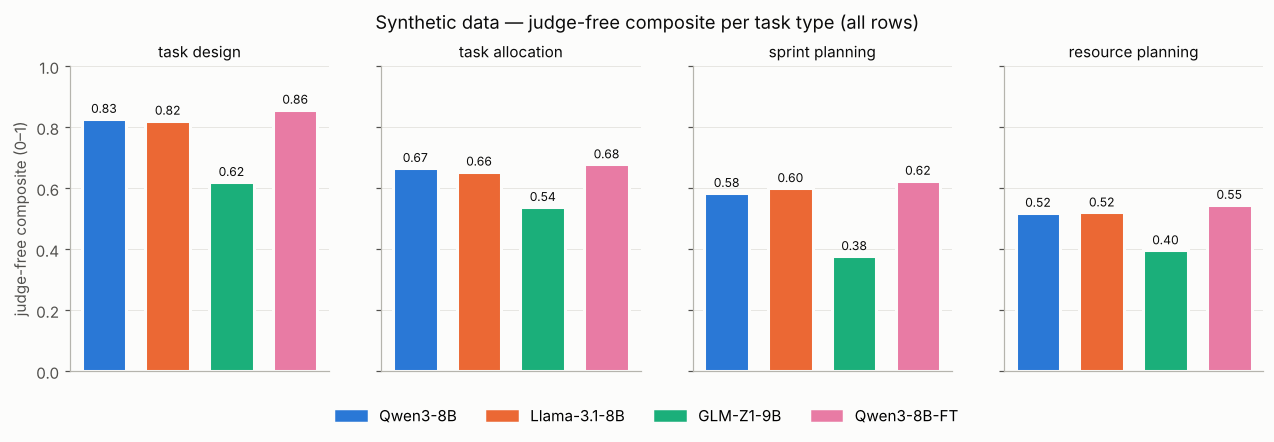

In [6]:
# ── Per-task view on synthetic data (all rows, judge-free metrics) ────────────
per_task = (syn.groupby(["task_type", "model"])[["auto_rouge_l", "auto_bert_score_f1", "composite_auto"]]
               .mean().round(3).unstack("model"))
per_task = per_task.reindex(columns=ordered(syn["model"].unique()), level=1)
display(per_task["composite_auto"])

# Small multiples: one panel per task, one bar per model (same colours everywhere)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
models = ordered(syn["model"].unique())
for ax, task in zip(axes, TASKS):
    vals = per_task["composite_auto"].loc[task, models]
    bars = ax.bar(range(len(models)), vals, color=[MODEL_COLORS[m] for m in models],
                  width=0.7, edgecolor="#fcfcfb", linewidth=2)
    for x, v in enumerate(vals):
        ax.text(x, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color="#0b0b0b")
    ax.set_title(task.replace("_", " "), fontsize=10, color="#0b0b0b")
    ax.set_xticks([]); ax.set_ylim(0, 1)
axes[0].set_ylabel("judge-free composite (0–1)")
handles = [plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[m]) for m in models]
fig.legend(handles, models, loc="lower center", ncol=len(models), frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Synthetic data — judge-free composite per task type (all rows)", color="#0b0b0b", y=1.02)
plt.show()

### 📊 Reading the output

The FT model is first on all four task types, by +0.01 (task allocation) to +0.04 (sprint planning) over base Qwen. Llama is slightly ahead of base Qwen on
sprint and resource planning and slightly behind on task design and allocation. GLM-Z1-9B is last everywhere.
Task design is the easiest task for every model; resource planning the hardest.

---
# Part B — Real Apache-Jira data (Notebooks 5 & 6)

## B1 · Load the 5-model real-data results

In [7]:
# ── Load the real-data results (5 models × 200 samples) ───────────────────────
real = pd.read_csv(REAL_CSV)
judge_cols = ["judge_relevance", "judge_completeness", "judge_feasibility",
              "judge_clarity", "judge_agile_alignment", "judge_overall"]
real[judge_cols + ["latency_s", "tokens_gen"]] = real[judge_cols + ["latency_s", "tokens_gen"]].apply(
    pd.to_numeric, errors="coerce")       # fixes the object-dtype error of Notebook 5's radar
real["response"] = real["response"].fillna("").astype(str)
real["reference"] = real["reference"].fillna("").astype(str)

cov = real.groupby("model").agg(rows=("sample_id", "size"), judged=("judge_overall", "count"),
                                judge_mean=("judge_overall", "mean"), latency_s=("latency_s", "mean"))
display(cov.loc[ordered(cov.index)].round(3))

,rows,judged,judge_mean,latency_s
model,,,,
Qwen3-8B,200,163,1.813,3.663
Llama-3.1-8B,200,164,1.916,2.770
GLM-Z1-9B,200,173,1.380,5.096
Gemini-3.5-Flash-Lite,200,145,2.332,1.504
Qwen3-8B-FT,200,145,1.825,1.046


### 📊 Reading the output

Each model answered the same 200 real prompts; 145–173 of them have a judge score. Averaged over all tracks the judge
ranks **Gemini 2.33 > Llama 1.92 > Qwen3-8B-FT 1.83 ≈ Qwen3-8B 1.81 > GLM 1.38** — every model scores far lower than on
synthetic data, and the FT model's advantage has disappeared. Latency: FT 1.05 s, Gemini 1.50 s (API), Llama 2.77 s,
Qwen 3.66 s, GLM 5.10 s.

## B2 · Re-score with the fixed JSON extractor

Notebook 5 wrote a better `extract_json` (keep the **last** JSON object, not first `{` to last `}`) but its tables still used
the old one. Here every answer is re-scored with the fixed extractor. Because the new extractor will happily return *any*
JSON object it finds — a roster entry copied from the prompt, or one task out of a cut-off list — a third column checks
that the object found is really an **answer** (it contains the track's key field: `acceptance_criteria`,
`assigned_to`, `selected_tasks` or `risk_flags`).

In [8]:
# ── Re-score every answer with the FIXED JSON extractor (Notebook 5, Cell 9a) ──
# Same metric definitions as Notebook 5, with two corrections:
#   1. extract_json keeps the LAST JSON object in the answer (not first '{' … last '}')
#   2. the real priority is read from the 'priority_known' column (Notebook 5's
#      re-scoring cell looked for a non-existent 'known_priority' column).
REQUIRED = {
    "task_design":       ["title", "description", "acceptance_criteria", "story_points", "priority"],
    "task_allocation":   ["assigned_to", "role", "rationale", "estimated_hours"],
    "sprint_planning":   ["sprint_goal", "selected_tasks", "scope_size", "excluded_tasks"],
    "resource_planning": ["capacity_constraints", "risk_flags", "mitigation_recommendations"],
}

# The one key that only a real answer contains (a roster entry also has "role",
# a single task object also has "title" — so these are chosen per track).
KEY_FIELD = {"task_design": "acceptance_criteria", "task_allocation": "assigned_to",
             "sprint_planning": "selected_tasks", "resource_planning": "risk_flags"}

def extract_json(text):
    clean = re.sub(r"```(?:json)?\s*", "", text).replace("```", "").strip()
    try:
        return json.loads(clean)
    except json.JSONDecodeError:
        pass
    dec, found = json.JSONDecoder(), []
    for i, ch in enumerate(clean):
        if ch in "{[":
            try:
                found.append(dec.raw_decode(clean, i)[0])
            except json.JSONDecodeError:
                continue
    dicts = [c for c in found if isinstance(c, dict)]
    return dicts[-1] if dicts else (found[-1] if found else None)

def first_number(text):
    m = re.search(r"[-+]?\d*\.?\d+", str(text or ""))
    return float(m.group(0)) if m else None

def ape(pred, real_v):
    """absolute percentage error |pred − real| / |real|"""
    try:
        pred, real_v = float(pred), float(real_v)
    except (TypeError, ValueError):
        return np.nan
    return np.nan if real_v == 0 or np.isnan(pred) or np.isnan(real_v) else abs(pred - real_v) / abs(real_v)

def rescore(row):
    parsed = extract_json(row["response"])
    obj = parsed[0] if isinstance(parsed, list) and parsed else parsed
    obj = obj if isinstance(obj, dict) else {}
    req = REQUIRED[row["task_type"]]
    out = {"valid_json_fixed": parsed is not None,                       # some JSON could be parsed
           "answer_found": KEY_FIELD[row["task_type"]] in obj,            # …and it is the ANSWER object
           "schema_fixed": sum(k in obj for k in req) / len(req)}
    t = row["task_type"]
    if t == "task_design":
        pred = str(obj.get("priority", "")).strip().capitalize()
        out["priority_match_fixed"] = float(pred == str(row["priority_known"]))
    elif t == "task_allocation":
        hrs = obj.get("estimated_hours")
        try:
            hrs = float(hrs)
        except (TypeError, ValueError):
            hrs = first_number(hrs) if hrs is not None else None
        out["assignee_match_fixed"] = float(str(obj.get("assigned_to", "")).strip().lower()
                                            == str(row["assignee_real"]).strip().lower())
        out["hours_ape_fixed"] = ape(hrs, row["hours_real"])
    elif t == "sprint_planning":
        try:
            ref = json.loads(row["reference"])
        except json.JSONDecodeError:
            ref = {}
        pred = obj.get("selected_tasks", [])
        pred = [str(p) for p in pred] if isinstance(pred, list) else []
        real_tasks, used, hit = ref.get("selected_tasks", []), set(), 0
        for p in pred:                                   # greedy one-to-one fuzzy match (ratio ≥ 0.6)
            for i, r in enumerate(real_tasks):
                if i not in used and difflib.SequenceMatcher(None, p.lower(), r.lower()).ratio() >= 0.6:
                    hit += 1; used.add(i); break
        prec = hit / len(pred) if pred else 0.0
        rec = hit / len(real_tasks) if real_tasks else 0.0
        out["taskset_f1_fixed"] = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        out["scope_ape_fixed"] = ape(obj.get("scope_size"), ref.get("scope_size"))
    return pd.Series(out)

real = pd.concat([real, real.apply(rescore, axis=1)], axis=1)

# Before / after, per track and model:
#   valid_json_orig  – original extractor found JSON
#   valid_json_fixed – fixed extractor found SOME JSON (can be a roster entry or one task object!)
#   answer_found     – the JSON found contains at least one key the task asked for
real["valid_json_orig"] = real["auto_valid_json"].astype(str).str.lower().isin(["true", "1", "1.0"])
for col in ["valid_json_orig", "valid_json_fixed", "answer_found"]:
    print(col)
    display(real.groupby(["task_type", "model"])[col].mean().unstack("model")
                .reindex(columns=ordered(real["model"].unique())).loc[TASKS].round(2))

valid_json_orig


model,Qwen3-8B,Llama-3.1-8B,GLM-Z1-9B,Gemini-3.5-Flash-Lite,Qwen3-8B-FT
task_type,,,,,
task_design,0.98,0.82,0.30,1.0,1.0
task_allocation,0.02,0.36,0.08,1.0,0.0
sprint_planning,0.58,0.58,0.04,0.3,0.0
resource_planning,1.00,0.36,0.10,1.0,1.0


valid_json_fixed


model,Qwen3-8B,Llama-3.1-8B,GLM-Z1-9B,Gemini-3.5-Flash-Lite,Qwen3-8B-FT
task_type,,,,,
task_design,1.00,1.00,0.54,1.00,1.00
task_allocation,1.00,0.78,0.90,1.00,1.00
sprint_planning,0.62,0.70,0.06,0.76,0.96
resource_planning,1.00,1.00,0.14,1.00,1.00


answer_found


model,Qwen3-8B,Llama-3.1-8B,GLM-Z1-9B,Gemini-3.5-Flash-Lite,Qwen3-8B-FT
task_type,,,,,
task_design,1.00,0.82,0.38,1.00,1.0
task_allocation,0.26,0.00,0.18,1.00,0.0
sprint_planning,0.38,0.40,0.00,0.08,0.0
resource_planning,1.00,0.36,0.06,1.00,1.0


### 📊 Reading the output

* "Valid JSON" jumps for almost every model with the fixed extractor (e.g. FT sprint planning 0.00 → 0.96), but
  **`answer_found` shows most of those are not answers**: FT sprint planning 0.00, Llama task allocation 0.00.
  `auto_valid_json` alone is therefore a misleading metric on real data.
* Where real answers exist, the old and new extractor agree closely (task design, resource planning).

## B3 · Why do task allocation and sprint planning fail? Two pipeline problems

**Problem 1 — prompt truncation (local models only).** `tokenizer(..., truncation=True, max_length=1024)` cuts the *end*
of long prompts: the instruction and the assistant header disappear and the model keeps writing the prompt.

**Problem 2 — output budget.** `MAX_NEW_TOKENS = 600` is shared by all models; long answers stop mid-JSON.

In [9]:
# ── Diagnose the prompt-truncation problem (max_length = 1,024 tokens) ─────────
# If the end of a prompt is cut off, the model never sees "Return JSON …" and the
# assistant header; it simply continues the input. Two symptoms are counted:
#   starts_mid_text – the answer does not begin with '{', '[', '<think' or a ``` fence
#   copies_prompt   – its first 15 characters appear verbatim in the prompt
real["prompt_chars"] = real["input"].astype(str).str.len()
real["starts_mid_text"] = ~real["response"].str.strip().str[:1].isin(["{", "[", "<", "`"])
real["copies_prompt"] = real.apply(lambda r: len(r["response"].strip()) >= 15
                                   and r["response"].strip()[:15] in str(r["input"]), axis=1)

print("Median prompt length (characters) per track:")
display(real.groupby("task_type")["prompt_chars"].median().astype(int).loc[TASKS].to_frame("median prompt chars"))
for col in ["starts_mid_text", "copies_prompt"]:
    print(col, "(share of answers)")
    display(real.groupby(["task_type", "model"])[col].mean().unstack("model")
                .reindex(columns=ordered(real["model"].unique())).loc[TASKS].round(2))

# A different problem: answers that stop mid-JSON because they used the whole
# 600-token budget (MAX_NEW_TOKENS) — the answer does not end with '}' or ']'.
real["cut_off"] = ~real["response"].str.rstrip().str.endswith(("}", "]"))
print("cut_off (share of answers that end mid-JSON)")
display(real.groupby(["task_type", "model"])["cut_off"].mean().unstack("model")
            .reindex(columns=ordered(real["model"].unique())).loc[TASKS].round(2))

Median prompt length (characters) per track:


,median prompt chars
task_type,
task_design,1120
task_allocation,4599
sprint_planning,2933
resource_planning,1094


starts_mid_text (share of answers)


model,Qwen3-8B,Llama-3.1-8B,GLM-Z1-9B,Gemini-3.5-Flash-Lite,Qwen3-8B-FT
task_type,,,,,
task_design,0.00,0.00,1.00,0.0,0.00
task_allocation,0.94,0.92,1.00,0.0,1.00
sprint_planning,0.18,0.18,0.96,0.0,0.18
resource_planning,0.00,0.00,1.00,0.0,0.00


copies_prompt (share of answers)


model,Qwen3-8B,Llama-3.1-8B,GLM-Z1-9B,Gemini-3.5-Flash-Lite,Qwen3-8B-FT
task_type,,,,,
task_design,0.00,0.00,0.00,0.0,0.00
task_allocation,0.56,0.66,0.78,0.0,0.40
sprint_planning,0.06,0.04,0.00,0.0,0.02
resource_planning,0.00,0.00,0.00,0.0,0.00


cut_off (share of answers that end mid-JSON)


model,Qwen3-8B,Llama-3.1-8B,GLM-Z1-9B,Gemini-3.5-Flash-Lite,Qwen3-8B-FT
task_type,,,,,
task_design,0.00,0.18,0.62,0.00,0.0
task_allocation,0.44,0.00,0.90,0.00,0.0
sprint_planning,0.60,0.54,1.00,0.92,0.9
resource_planning,0.00,0.44,0.94,0.00,0.0


### 📊 Reading the output

* **Task-allocation prompts are ~4,600 characters** (≈ 4× the others). For the local models 56–78 % of the answers
  start with text copied **verbatim** from the prompt (Gemini: 0 %), and almost none start with `{`. This is the
  truncation bug — local-model task-allocation scores do not measure allocation skill. (GLM's `starts_mid_text` is 1.00
  everywhere because it always begins with plain-text reasoning.)
* **Sprint planning is limited by the 600-token budget:** 92 % of Gemini's and 90 % of the FT model's sprint answers stop
  mid-JSON; Qwen and Llama about 55–60 %. GLM runs out of tokens on almost every track (reasoning first).

## B4 · Per-track results, all 5 models (corrected scoring)

* task design: majority-class baseline added for priority match
* task allocation: hours error reported as the **median** absolute percentage error (the mean is dominated by tiny real values)
* resource planning: velocity error left out — the prompt states the real velocity, so repeating it scores 0 error

In [10]:
# ── Per-track tables, all 5 models (fixed scoring) ────────────────────────────
def track_table(task, cols):
    sub = real[real["task_type"] == task]
    t = sub.groupby("model").agg(**{c: (c, "mean") for c in cols},
                                 judge=("judge_overall", "mean"), judged_n=("judge_overall", "count"))
    return t.loc[ordered(t.index)].round(3)

td = track_table("task_design", ["answer_found", "schema_fixed", "priority_match_fixed"])
majority = real.loc[(real.task_type == "task_design") & (real.model == "Qwen3-8B"), "priority_known"].value_counts(normalize=True)
print(f"Task design — majority-class baseline: always answer '{majority.index[0]}' → priority match {majority.iloc[0]:.2f}")
display(td)

ta = track_table("task_allocation", ["answer_found", "assignee_match_fixed"])
ta["hours_APE_median"] = (real[real.task_type == "task_allocation"]
                          .groupby("model")["hours_ape_fixed"].median().round(2))
print("Task allocation (⚠️ local models affected by prompt truncation)")
display(ta)

print("Sprint planning")
display(track_table("sprint_planning", ["answer_found", "taskset_f1_fixed", "scope_ape_fixed"]))

print("Resource planning (velocity error omitted: the prompt states the velocity)")
display(track_table("resource_planning", ["answer_found", "schema_fixed"]))

Task design — majority-class baseline: always answer 'High' → priority match 0.54


,answer_found,schema_fixed,priority_match_fixed,judge,judged_n
model,,,,,
Qwen3-8B,1.00,1.00,0.48,2.128,40
Llama-3.1-8B,0.82,0.82,0.40,2.690,31
GLM-Z1-9B,0.38,0.38,0.18,1.746,46
Gemini-3.5-Flash-Lite,1.00,1.00,0.48,2.823,31
Qwen3-8B-FT,1.00,1.00,0.42,2.676,34


Task allocation (⚠️ local models affected by prompt truncation)


,answer_found,assignee_match_fixed,judge,judged_n,hours_APE_median
model,,,,,
Qwen3-8B,0.26,0.06,1.260,45,–
Llama-3.1-8B,0.00,0.00,1.139,49,–
GLM-Z1-9B,0.18,0.02,1.138,47,–
Gemini-3.5-Flash-Lite,1.00,0.24,2.156,32,20.43
Qwen3-8B-FT,0.00,0.00,1.165,26,–


Sprint planning


,answer_found,taskset_f1_fixed,scope_ape_fixed,judge,judged_n
model,,,,,
Qwen3-8B,0.38,0.269,0.386,2.413,38
Llama-3.1-8B,0.40,0.279,0.367,2.456,41
GLM-Z1-9B,0.00,0.000,–,1.397,33
Gemini-3.5-Flash-Lite,0.08,0.060,0.635,2.735,40
Qwen3-8B-FT,0.00,0.000,–,1.864,39


Resource planning (velocity error omitted: the prompt states the velocity)


,answer_found,schema_fixed,judge,judged_n
model,,,,
Qwen3-8B,1.00,1.00,1.550,40
Llama-3.1-8B,0.36,0.36,1.730,43
GLM-Z1-9B,0.06,0.06,1.251,47
Gemini-3.5-Flash-Lite,1.00,1.00,1.721,42
Qwen3-8B-FT,1.00,1.00,1.535,46


### 📊 Reading the output

| Track | Takeaway |
|---|---|
| **Task design** | The FT model improves on base Qwen (judge **2.13 → 2.68**) and now matches Llama (2.69), close to Gemini (2.82). No model beats the trivial "always High" priority baseline (0.54). |
| **Task allocation** | Only Gemini produces real answers (24 % exact assignee, median hours error ≈ 20× the logged hours). Local-model numbers are invalid because of truncation. |
| **Sprint planning** | Llama (F1 0.28) ≈ base Qwen (0.27) are best; Gemini and FT are cut off by the token limit (F1 0.06 and 0.00). |
| **Resource planning** | All models are judged poorly (1.25–1.73); Qwen, FT and Gemini always return the full schema, Llama only 36 %. |

## B5 · Fine-tuned vs base Qwen3-8B on real data (paired tests)

Both models answered the **same** 200 prompts, so paired tests are valid here: Wilcoxon signed-rank for judge scores and
F1, exact McNemar (binomial test on discordant pairs) for the binary priority match.

In [11]:
# ── Is the fine-tuned model better than base Qwen3-8B on real data? ───────────
# Here both models answered the SAME 200 prompts, so paired tests are valid.
def paired(task, metric, kind):
    sub = real[real["task_type"] == task]
    pv = sub.pivot_table(index="sample_id", columns="model", values=metric)[["Qwen3-8B", "Qwen3-8B-FT"]].dropna()
    a, b = pv["Qwen3-8B-FT"], pv["Qwen3-8B"]
    d = a - b
    if kind == "wilcoxon":
        p = stats.wilcoxon(a, b).pvalue if (d != 0).any() else np.nan
    else:   # exact McNemar = binomial test on the discordant pairs
        n01, n10 = int(((a == 1) & (b == 0)).sum()), int(((a == 0) & (b == 1)).sum())
        p = stats.binomtest(n01, n01 + n10).pvalue if n01 + n10 else np.nan
    return {"track": task, "metric": metric, "test": kind, "n_pairs": len(pv),
            "base Qwen3-8B": round(b.mean(), 3), "Qwen3-8B-FT": round(a.mean(), 3),
            "Δ": round(d.mean(), 3), "p": round(p, 4) if not np.isnan(p) else "–"}

tests = pd.DataFrame([
    paired("task_design", "judge_overall", "wilcoxon"),
    paired("task_design", "priority_match_fixed", "mcnemar"),
    paired("task_allocation", "judge_overall", "wilcoxon"),
    paired("sprint_planning", "judge_overall", "wilcoxon"),
    paired("sprint_planning", "taskset_f1_fixed", "wilcoxon"),
    paired("resource_planning", "judge_overall", "wilcoxon"),
]).set_index(["track", "metric"])
display(tests)

test  n_pairs  base Qwen3-8B  Qwen3-8B-FT      Δ       p
track             metric                                                                            
task_design       judge_overall         wilcoxon       26          1.900        2.650  0.750  0.0001
                  priority_match_fixed   mcnemar       50          0.480        0.420 -0.060  0.5488
task_allocation   judge_overall         wilcoxon       24          1.238        1.138 -0.100  0.3023
sprint_planning   judge_overall         wilcoxon       32          2.294        1.809 -0.484  0.0009
                  taskset_f1_fixed      wilcoxon       50          0.269        0.000 -0.269  0.0001
resource_planning judge_overall         wilcoxon       36          1.556        1.500 -0.056  0.7572

### 📊 Reading the output

| Track | FT vs base | Verdict |
|---|---|---|
| Task design (judge) | **+0.75**, p = 0.0001 (26 pairs) | ✅ fine-tuning helps |
| Task design (priority) | −0.06, p = 0.55 | no difference |
| Task allocation (judge) | −0.10, p = 0.30 | no difference (both broken by truncation) |
| Sprint planning (judge / F1) | **−0.48**, p = 0.0009 / **−0.27**, p = 0.0001 | ❌ fine-tuning hurts |
| Resource planning (judge) | −0.06, p = 0.76 | no difference |

The FT model learned the **synthetic output formats**. Where the real prompt asks for the same format (task design) that
helps; where it asks for a different one (sprint planning wants a list of titles + `scope_size`, the FT model writes a rich
object per task and runs out of tokens) it hurts.

## B6 · Charts — judge score per track, and the judge radar

The radar is the chart that failed in Notebooks 5 and 6 (`TypeError … dtype->object`); converting the judge columns to
numbers in B1 fixes it. Bar labels show the mean and the number of judged answers (`n`).

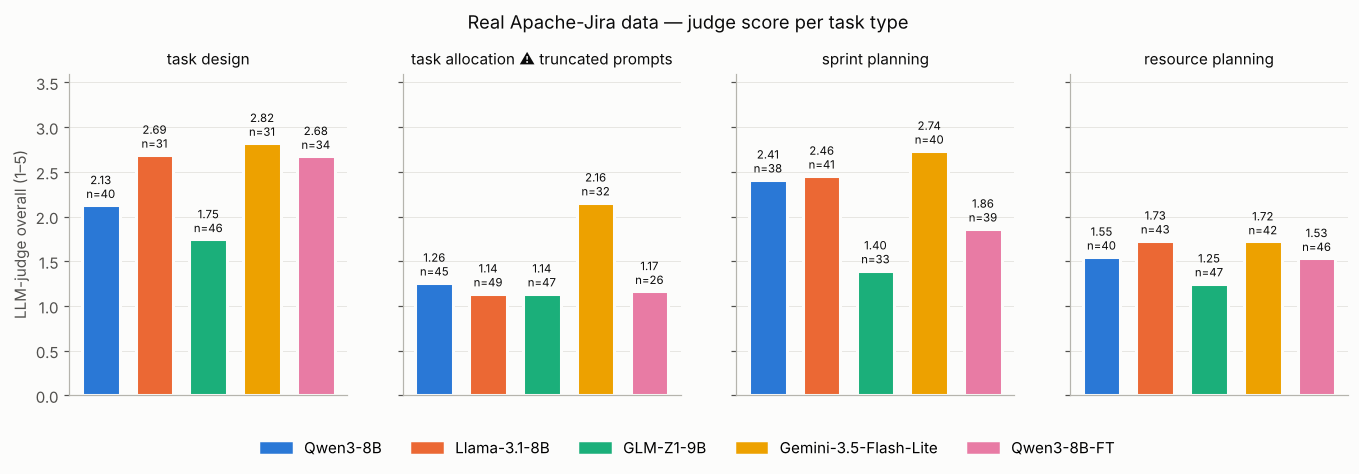

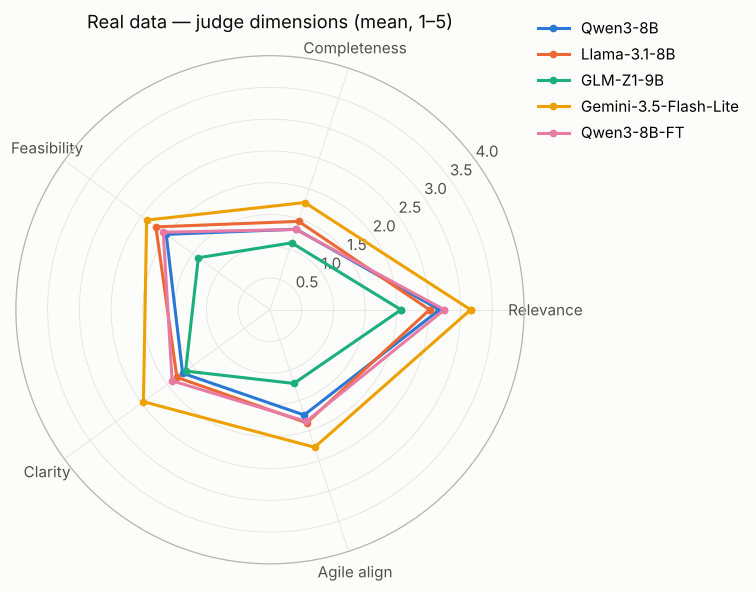

In [12]:
# ── Real data: judge score per track, 5 models (with how many rows were judged) ──
jt = real.groupby(["task_type", "model"])["judge_overall"].agg(["mean", "count"]).reset_index()
models = ordered(real["model"].unique())
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, task in zip(axes, TASKS):
    sub = jt[jt.task_type == task].set_index("model").loc[models]
    ax.bar(range(len(models)), sub["mean"], color=[MODEL_COLORS[m] for m in models],
           width=0.7, edgecolor="#fcfcfb", linewidth=2)
    for x, (v, n) in enumerate(zip(sub["mean"], sub["count"])):
        ax.text(x, v + 0.05, f"{v:.2f}\nn={n}", ha="center", va="bottom", fontsize=7.5, color="#0b0b0b")
    ax.set_title(task.replace("_", " ") + (" ⚠️ truncated prompts" if task == "task_allocation" else ""),
                 fontsize=10, color="#0b0b0b")
    ax.set_xticks([]); ax.set_ylim(0, 3.6)
axes[0].set_ylabel("LLM-judge overall (1–5)")
handles = [plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[m]) for m in models]
fig.legend(handles, models, loc="lower center", ncol=len(models), frameon=False, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Real Apache-Jira data — judge score per task type", color="#0b0b0b", y=1.03)
plt.show()

# Judge radar (all tracks pooled) — the version that failed in Notebook 5
dims = ["judge_relevance", "judge_completeness", "judge_feasibility", "judge_clarity", "judge_agile_alignment"]
agg = real.groupby("model")[dims].mean().loc[models]
ang = np.linspace(0, 2 * np.pi, len(dims), endpoint=False).tolist() + [0]
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
for m in models:
    v = agg.loc[m].tolist(); v += v[:1]
    ax.plot(ang, v, "-o", lw=2, ms=4, color=MODEL_COLORS[m], label=m)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(["Relevance", "Completeness", "Feasibility", "Clarity", "Agile align"])
ax.set_ylim(0, 4); ax.set_rlabel_position(36)   # radial tick labels between two axes
ax.set_title("Real data — judge dimensions (mean, 1–5)", color="#0b0b0b", pad=18)
ax.legend(loc="upper right", bbox_to_anchor=(1.45, 1.1), frameon=False)
plt.show()

---
# Part C — Synthetic vs real: does the ranking carry over?

Judge overall per model on both datasets. The real-data column is also shown **without task allocation**, so the
truncation bug does not drive the comparison.

,judge synthetic,judge real (all tracks),judge real (excl. task allocation),drop synthetic → real (excl. alloc)
model,,,,
Qwen3-8B,2.31,1.81,2.02,-0.29
Llama-3.1-8B,2.38,1.92,2.25,-0.13
GLM-Z1-9B,1.58,1.38,1.47,-0.11
Gemini-3.5-Flash-Lite,2.51,2.33,2.38,-0.13
Qwen3-8B-FT,3.47,1.82,1.97,-1.50


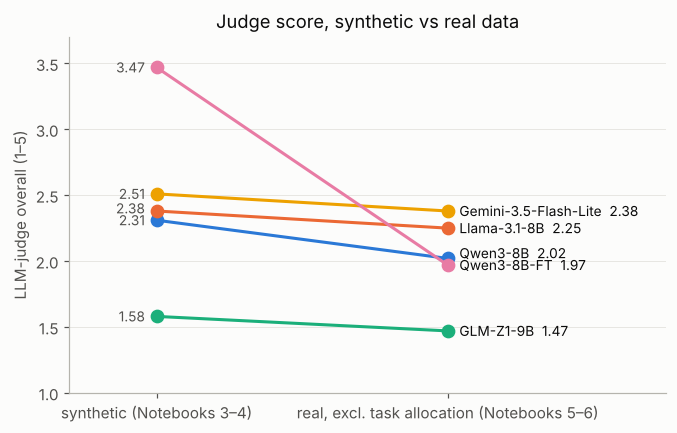

In [13]:
# ── Synthetic vs real: does the ranking hold? ─────────────────────────────────
syn_j = syn.groupby("model")["judge_overall"].mean()
syn_j["Gemini-3.5-Flash-Lite"] = 2.509                       # from Notebook 3's output
real_j_all = real.groupby("model")["judge_overall"].mean()
real_j_noalloc = real[real.task_type != "task_allocation"].groupby("model")["judge_overall"].mean()

cross = pd.DataFrame({"judge synthetic": syn_j, "judge real (all tracks)": real_j_all,
                      "judge real (excl. task allocation)": real_j_noalloc}).loc[MODEL_ORDER].round(2)
cross["drop synthetic → real (excl. alloc)"] = (cross["judge real (excl. task allocation)"]
                                               - cross["judge synthetic"]).round(2)
display(cross)

def spread(values, gap=0.09):
    """Nudge label positions apart so neighbouring labels never overlap."""
    order = sorted(values, key=values.get)
    pos, last = {}, -np.inf
    for k in order:
        pos[k] = max(values[k], last + gap); last = pos[k]
    return pos

fig, ax = plt.subplots(figsize=(7, 4.2))
left  = spread({m: cross.loc[m, "judge synthetic"] for m in MODEL_ORDER})
right = spread({m: cross.loc[m, "judge real (excl. task allocation)"] for m in MODEL_ORDER})
for m in MODEL_ORDER:
    y0, y1 = cross.loc[m, "judge synthetic"], cross.loc[m, "judge real (excl. task allocation)"]
    ax.plot([0, 1], [y0, y1], "-o", lw=2, ms=8, color=MODEL_COLORS[m])
    ax.text(1.04, right[m], f"{m}  {y1:.2f}", va="center", fontsize=9, color="#0b0b0b")
    ax.text(-0.04, left[m], f"{y0:.2f}", va="center", ha="right", fontsize=9, color="#52514e")
ax.set_xticks([0, 1]); ax.set_xticklabels(["synthetic (Notebooks 3–4)", "real, excl. task allocation (Notebooks 5–6)"])
ax.set_xlim(-0.3, 1.75); ax.set_ylim(1, 3.7); ax.set_ylabel("LLM-judge overall (1–5)")
ax.grid(axis="x", visible=False)
ax.set_title("Judge score, synthetic vs real data", color="#0b0b0b")
plt.show()

### 📊 Reading the output

* Every model scores lower on real data, but the **base models drop only 0.1–0.3 points** (excluding task allocation),
  and their order stays the same: **Gemini > Llama > Qwen > GLM**.
* The **fine-tuned model drops 1.50 points** — from first place on synthetic data (3.47) to roughly base-Qwen level on
  real data (1.97 vs 2.02). Its synthetic advantage does not transfer.
* Gemini, middle of the pack on the synthetic composite, is the strongest model on real data.

In [14]:
# ── Save the final tables (CSV) next to this notebook ─────────────────────────
import os
os.makedirs("final_tables", exist_ok=True)
pub.to_csv("final_tables/synthetic_published.csv")
rob.to_csv("final_tables/synthetic_robustness.csv")
td.to_csv("final_tables/real_task_design.csv")
ta.to_csv("final_tables/real_task_allocation.csv")
tests.to_csv("final_tables/real_ft_vs_base_tests.csv")
cross.to_csv("final_tables/synthetic_vs_real_judge.csv")
print("💾 saved:", sorted(os.listdir("final_tables")))

💾 saved: ['real_ft_vs_base_tests.csv', 'real_task_allocation.csv', 'real_task_design.csv', 'synthetic_published.csv', 'synthetic_robustness.csv', 'synthetic_vs_real_judge.csv']


---
# Part D — Conclusions and checklist for the paper

### What the results support

1. **On synthetic data, QLoRA fine-tuning clearly improves Qwen3-8B** on reference-based metrics that use every sample
   (ROUGE-L +0.09, BERTScore +0.02, judge-free composite +0.035, all highly significant), and the model ranking
   FT > Qwen ≈ Llama > GLM is stable whether or not the judge is included.
2. **Among the untuned models, Qwen3-8B and Llama-3.1-8B are statistically tied** on synthetic data; GLM-Z1-9B is clearly last
   (it spends its token budget on reasoning).
3. **On real Apache-Jira data the base-model ranking holds** (Gemini > Llama > Qwen > GLM), with modest drops in judge score.
4. **The fine-tuning gain does not transfer to real data.** It helps on task design (+0.75 judge, p = 0.0001), hurts on
   sprint planning (−0.48 judge, F1 0.27 → 0.00) and is neutral elsewhere. The adapter mostly learned synthetic formats.

### What needs fixing or a caveat before publication

| # | Issue | Affects | Suggested action |
|---|---|---|---|
| 1 | Judge failed on 383/470 FT synthetic answers; composite averages only judged rows | README table, Notebook 4 | re-run the judge on missing rows, or report the judge-free composite next to it |
| 2 | FT synthetic test set ≠ baseline test set; paired Wilcoxon on 12 pairs | Notebook 4 Cell 13 | evaluate baselines on the FT test split, or report unpaired tests (A4) |
| 3 | FT `tokens_gen` counts batch padding → tok/s overstated | README "~5× throughput" | count non-pad tokens, then recompute |
| 4 | Prompts truncated at 1,024 tokens for local models | real task allocation (and some sprint) | raise `max_length` / `truncation_side="left"`, re-run task allocation |
| 5 | `MAX_NEW_TOKENS = 600` too small for real sprint plans | Gemini, FT sprint planning | raise to ~1,500 for sprint planning |
| 6 | Judge sees only 500 characters of each answer | all real-data judge scores | raise the limit (e.g. 2,000) |
| 7 | Velocity MAPE ≈ 0 because the prompt states the velocity | real resource planning | drop the metric or remove the number from the prompt |
| 8 | Priority match below the "always High" baseline (0.54) | real task design | report against the majority baseline |
| 9 | Different judge prompts in Notebooks 3 and 4 | synthetic judge scores of FT vs baselines | re-judge all models with one prompt |
| 10 | Live API keys were hard-coded in the original notebooks | security | rotate those keys; keep them in environment variables / Colab Secrets |